In [1]:
# importing libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

In [2]:
waves = pd.read_csv(r"C:\Users\justi\OneDrive\Documents\GEOL_415\Assignments\Data\Waves_2023.txt", sep=r'\s+')

In [3]:
print(waves.columns.tolist())

['YY', 'MM', 'DD', 'hh', 'mm', 'WDIR', 'WSPD', 'GST', 'WVHT', 'DPD', 'APD', 'MWD', 'PRES', 'ATMP', 'WTMP', 'DEWP', 'VIS', 'TIDE']


In [4]:
features = ['DPD', 'APD', 'MWD', 'WTMP']
target = 'WVHT'

In [5]:
data = waves[features + [target]].copy()

In [6]:
data = data.apply(pd.to_numeric, errors='coerce')


In [7]:
missing_codes = [99, 99.0, 999, 999.0, 9999, 9999.0]
data = data.replace(missing_codes, np.nan)

In [8]:
data = data.dropna()


In [9]:
data = data[
    (data['WVHT'] >= 0) &
    (data['DPD'] > 0) &
    (data['APD'] > 0) &
    data['MWD'].between(0, 360) &
    data['WTMP'].between(-5, 50)
]

X = data[features]
y = data[target]

print("Number of usable observations:", len(data))
print(data.describe())

Number of usable observations: 17276
                DPD           APD           MWD          WTMP          WVHT
count  17276.000000  17276.000000  17276.000000  17276.000000  17276.000000
mean      12.116640      6.765029    234.157965     17.195294      1.032525
std        3.664928      1.852623     46.260000      2.564729      0.526637
min        2.860000      3.420000     10.000000     11.800000      0.330000
25%        9.090000      5.500000    179.000000     14.600000      0.730000
50%       12.500000      6.360000    263.000000     17.500000      0.880000
75%       14.290000      7.550000    271.000000     19.400000      1.140000
max       25.000000     15.790000    306.000000     23.900000      5.130000


In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Test observations:", len(X_test))


Training observations: 10365
Validation observations: 3455
Test observations: 3456


In [11]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest (25 trees)': RandomForestRegressor(
        n_estimators=25,
        random_state=42,
        n_jobs=-1
    )
}


In [12]:
results = []

for name, model in models.items():

    # Fit the model using training data only
    model.fit(X_train, y_train)

    # Evaluate each dataset
    for dataset_name, X_set, y_set in [
        ('Training', X_train, y_train),
        ('Validation', X_val, y_val),
        ('Test', X_test, y_test)
    ]:

        predictions = model.predict(X_set)

        rmse = np.sqrt(
            mean_squared_error(y_set, predictions)
        )

        r2 = r2_score(y_set, predictions)

        results.append({
            'Model': name,
            'Dataset': dataset_name,
            'RMSE': rmse,
            'R2': r2
        })

In [13]:
results_df = pd.DataFrame(results)

print("\nModel Performance:")
print(results_df.round(4).to_string(index=False))


Model Performance:
                   Model    Dataset   RMSE     R2
       Linear Regression   Training 0.4443 0.2984
       Linear Regression Validation 0.4478 0.2852
       Linear Regression       Test 0.4313 0.2899
           Decision Tree   Training 0.0054 0.9999
           Decision Tree Validation 0.3913 0.4540
           Decision Tree       Test 0.3874 0.4273
Random Forest (25 trees)   Training 0.1144 0.9535
Random Forest (25 trees) Validation 0.2921 0.6958
Random Forest (25 trees)       Test 0.2840 0.6921


In [14]:
validation_results = results_df[
    results_df['Dataset'] == 'Validation'
].sort_values('RMSE')

print("\nModels ranked by validation RMSE:")
print(validation_results[['Model', 'RMSE', 'R2']].round(4))

print("\nBest model based on validation RMSE:")
print(validation_results.iloc[0]['Model'])


Models ranked by validation RMSE:
                      Model    RMSE      R2
7  Random Forest (25 trees)  0.2921  0.6958
4             Decision Tree  0.3913  0.4540
1         Linear Regression  0.4478  0.2852

Best model based on validation RMSE:
Random Forest (25 trees)


In [15]:
n_trees = [2, 10, 25, 50, 100, 250, 500, 1000]

In [16]:
train_errors = []
val_errors = []

for n in n_trees:

    # Train random forest
    rf = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

In [17]:
train_pred = rf.predict(X_train)
val_pred = rf.predict(X_val)

In [18]:
# Calculate RMSE
train_rmse = np.sqrt(
mean_squared_error(y_train, train_pred))

val_rmse = np.sqrt(
mean_squared_error(y_val, val_pred)
    )

train_errors.append(train_rmse)
val_errors.append(val_rmse)

print(
f"Trees: {n:4d} | "
f"Training RMSE: {train_rmse:.4f} | "
f"Validation RMSE: {val_rmse:.4f}"
    )

Trees: 1000 | Training RMSE: 0.1052 | Validation RMSE: 0.2876


In [19]:
n_trees = [2, 10, 25, 50, 100, 250, 500, 1000]


In [20]:
train_errors = []
val_errors = []

In [21]:
for n in n_trees:
    rf = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    train_pred = rf.predict(X_train)
    val_pred = rf.predict(X_val)

    train_errors.append(
        np.sqrt(mean_squared_error(y_train, train_pred))
    )

    val_errors.append(
        np.sqrt(mean_squared_error(y_val, val_pred))
    )

In [22]:
print("Tree counts:", len(n_trees))
print("Training errors:", len(train_errors))
print("Validation errors:", len(val_errors))

Tree counts: 8
Training errors: 8
Validation errors: 8


In [23]:
results_rf = pd.DataFrame({
    'Number of Trees': n_trees,
    'Training RMSE': train_errors,
    'Validation RMSE': val_errors
})

print(results_rf.round(4).to_string(index=False))

 Number of Trees  Training RMSE  Validation RMSE
               2         0.1829           0.3475
              10         0.1269           0.3048
              25         0.1144           0.2921
              50         0.1088           0.2890
             100         0.1072           0.2878
             250         0.1060           0.2879
             500         0.1056           0.2874
            1000         0.1052           0.2876


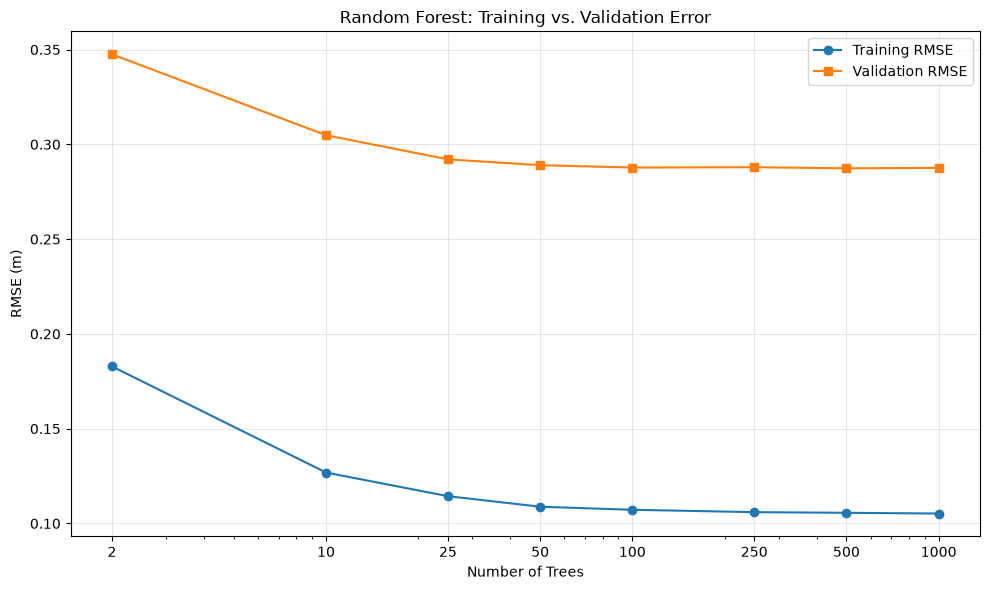

In [24]:
plt.figure(figsize=(10, 6))
plt.plot(n_trees, train_errors, marker='o', label='Training RMSE')
plt.plot(n_trees, val_errors, marker='s', label='Validation RMSE')

plt.xscale('log')
plt.xticks(n_trees, labels=n_trees)
plt.xlabel('Number of Trees')
plt.ylabel('RMSE (m)')
plt.title('Random Forest: Training vs. Validation Error')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
#1. Linear regression: Baseline model that fits a linear relationship between the four predictors and wave height.
    # Decision tree regressor: Learns nonlinear relationships by splitting the data into groups.
    # Random forest regressor: Combines 25 decision trees to reduce the variance of individual trees.
    # RMSE: Measures typical prediction error in meters. Lower is better.
    # R^2: Measures how much variation in wave height the model explains. Higher is better; it can be negative on unseen data.
#2. Cost function is RMSE
#3. We optomized the number of trees tested.
#4. No because of the randomization of the different regression trees
#6. We do start to see overfitting at the 1000 tree data set as the validation number starts increasing from the lowest value of 500 trees. 